# Electrostatic simulations for superconducting circuits

In [1]:
import os
os.environ.setdefault("QISKIT_METAL_HEADLESS", "1")
os.environ.setdefault("QT_QPA_PLATFORM", "offscreen")
os.environ.setdefault("MPLBACKEND", "Agg")

import qiskit_metal as metal
from qiskit_metal import designs, draw, view
from qiskit_metal import Dict, Headings


from qiskit_metal.qlibrary.qubits.transmon_pocket import TransmonPocket


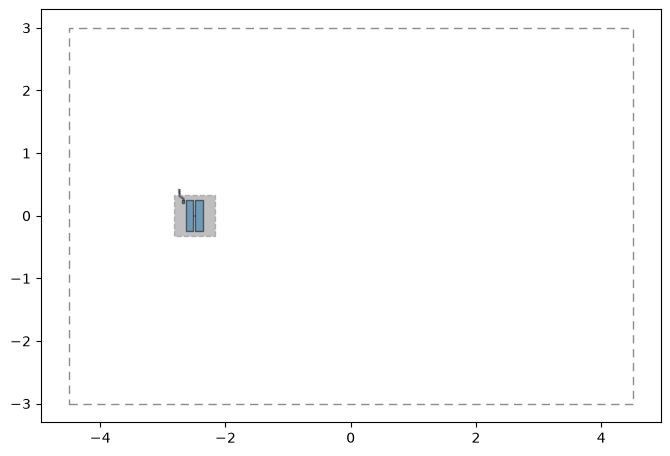

In [ ]:
design = designs.DesignPlanar({}, overwrite_enabled=True)
design.delete_all_components()

design = designs.DesignPlanar()
design.overwrite_enabled = True

design.chips.main.size['size_x'] = '9mm'
design.chips.main.size['size_y'] = '6mm'




pad_opts = Dict(pad_width='50um', pad_height='30um', pad_gap='30um')

q0 = TransmonPocket(design, 'Q0', options=Dict(
    pos_x=f'-2.5 mm', pos_y=f'0 mm', orientation=90, pad_width='500um', pad_height='120 um', pocket_height='650um',
    connection_pads=Dict(
        readout=Dict(loc_W=+1, loc_H=+1, **pad_opts),
    )))

design.rebuild()

%matplotlib inline
view(design)


Electrostatic simulations only capture the capacitive properties of a device and are used to extract quantities such as capacitance matrices and charging energies. Since a Josephson junction contributes a nonlinear inductance rather than a significant capacitance, it has little impact on the electrostatic solution and is typically omitted. Its effect is instead incorporated later through the Josephson energy, $E_J$, when constructing the circuit Hamiltonian with LOM.

# Mesh Quantum Metal design

In [3]:
from pypalace import mesh

In [4]:
surface_table = mesh.get_quantum_metal_surfaces(design)
surface_table

,component_id,component_name,name,subtract
0,1,Q0,pad_top,False
1,1,Q0,pad_bot,False
2,1,Q0,rect_pk,True
3,1,Q0,readout_connector_pad,False
4,1,Q0,readout_wire,False
5,1,Q0,readout_wire_sub,True


Polygons with `subtract == True` are the designs' metal (superconducting thin-film) components, while polygons with `subtract == False` are etched regions. We will want to give all metal components some boundary condition, so we need to give all of these mesh attributes. 

In [5]:

attributes = {}


mesh_num = 1
for row in range(len(surface_table)):
    this_component = surface_table.iloc[row]
    if this_component["subtract"] == False:
        name = this_component["name"]
        comp_id = this_component["component_id"]
        attributes[(comp_id,name)] = mesh_num
        mesh_num += 1 

attributes 

{(1, 'pad_top'): 1,
 (1, 'pad_bot'): 2,
 (1, 'readout_connector_pad'): 3,
 (1, 'readout_wire'): 4}

## Mesh the design

now that we have defined a dictionary for the Quantum Metal surfaces we want to give boundary conditions, we can actually mesh our design:

In [6]:
mesh_dir = "mesh/"
meshfile = "electrostatic_lom.msh"
path_to_mesh = mesh_dir + meshfile

attributes_table = mesh.mesh_Quantum_Metal_design(design,
                                                  output_mesh=path_to_mesh,
                                                  Attributes=attributes);

Info    : Meshing 1D...nts                                                                                                                
Info    : [  0%] Meshing curve 25 (Line)
Info    : [ 10%] Meshing curve 26 (Line)
Info    : [ 10%] Meshing curve 27 (Line)
Info    : [ 10%] Meshing curve 28 (Line)
Info    : [ 10%] Meshing curve 29 (Line)
Info    : [ 10%] Meshing curve 30 (Line)
Info    : [ 10%] Meshing curve 31 (Line)
Info    : [ 20%] Meshing curve 32 (Line)
Info    : [ 20%] Meshing curve 47 (Line)
Info    : [ 20%] Meshing curve 48 (Line)
Info    : [ 20%] Meshing curve 49 (Line)
Info    : [ 20%] Meshing curve 50 (Line)
Info    : [ 20%] Meshing curve 51 (Line)
Info    : [ 30%] Meshing curve 52 (Line)
Info    : [ 30%] Meshing curve 53 (Line)
Info    : [ 30%] Meshing curve 54 (Line)
Info    : [ 30%] Meshing curve 55 (Line)
Info    : [ 30%] Meshing curve 56 (Line)
Info    : [ 30%] Meshing curve 57 (Line)
Info    : [ 40%] Meshing curve 58 (Line)
Info    : [ 40%] Meshing curve 59 (Line)


`pypalace.mesh.mesh_Quantum_Metal_design` returns an ordered dataframe of the mesh components. We will use these to build our Palace configuration file. Notice this function automatically makes a ground plane, an air box, a substrate box, and the far field. 

In [7]:
attributes_table

,Name,ID,Type
0,1__pad_top,1,Surface
1,1__pad_bot,2,Surface
2,1__readout_connector_pad,3,Surface
3,1__readout_wire,4,Surface
6,substrate,5,Volume
7,air,6,Volume
4,ground_plane,7,Surface
5,far_field,8,Surface


# Build Palace configuration file

pyPalace follows the Palace configuration schema one-to-one. In this sense, the pyPalace configuration building using `pypalace.Config` and `pypalace.builder` follows directly from the [Palace config documentation](https://awslabs.github.io/palace/stable/config/config/).

In [8]:
from pypalace import Config
from pypalace.builder import Model, Domains, Boundaries, Solver  # these match one-to-one with Palace config syntax

In [9]:
''' choose path & name for Palace configuration file we will build below '''
config_dir = "./"
path_to_config = config_dir + "electrostatic_lom.json"

## Initialize pyPalace Config object:

In [10]:
electrostatic_config = Config(path_to_config)

## Add `config["Problems"]` and `config["Model"]`

In [11]:
electrostatic_config.add_Problem(Type="Electrostatic",
                             Output="electrostatic_output")

# don't use here but this is how we could add adaptive mesh refinement
#AMR = Model.Refinement(Tol = 1e-6,MaxIts = 3)

# define config["Model"] block
electrostatic_config.add_Model(Mesh = path_to_mesh, # point to our meshfile
                    L0 = 1e-6,# mesh units relative to meters
                    #Refinement=AMR
                    ) 

## Add `config["Domains"]`

Used to define properties and postprocessing for meshed volumes.

In [12]:
# from the attribute table above:
substrate_id = 5
airbox_id = 6

# define materials
silicon = Domains.Material(Attributes = [substrate_id], # attributes to give the properties below to:
                                     Permeability=1.0, # magnetic permeability
                                     Permittivity=11.45, # electric permittivity
                                     LossTan=1e-07) # bulk loss tangent

airbox = Domains.Material([airbox_id],1.0,1.0,0.0)

# will not use this here but an example of adding domain postprocessing:


materials = [silicon,airbox] # material list for input into add_Domains()
electrostatic_config.add_Domains(Materials = materials) # add materials to our configuration file

## Add `config["Boundaries"]`

Used to define boundary conditions and postprocessing for meshed surfaces.

### Some notes on boundary conditions for electrostatic simulations of superconducting circuits
### <u>What are terminals?</u>

Terminals identify the conductors that should be included in the capacitance extraction. Palace excites each terminal one-by-one and computes the resulting charge distribution, allowing the mutual capacitances between conductors to be calculated. In superconducting circuits, terminals typically correspond to qubit pads, couplers, resonators, or other electrically distinct metal structures.

### <u>Why don't electrostatic simulations use PEC boundaries?</u>

In electrostatic simulations, the conductors of interest are already defined as terminals. The solver then computes the charge distribution on these conductors to determine their mutual capacitances. Applying a PEC boundary condition would instead fix a conductor as an equipotential surface outside of the capacitance extraction procedure, preventing Palace from treating it as an independent conductor in the capacitance matrix. *The ground plane and far field are given grounded boundary conditions*

In [13]:
attributes_table

,Name,ID,Type
0,1__pad_top,1,Surface
1,1__pad_bot,2,Surface
2,1__readout_connector_pad,3,Surface
3,1__readout_wire,4,Surface
6,substrate,5,Volume
7,air,6,Volume
4,ground_plane,7,Surface
5,far_field,8,Surface


In [14]:
# using attributes_table returned from meshing:
# mesh IDs for metals / PECs 
pad_top_id = 1
pad_bot_id = 2

readout_connector_pad_id = 3
readout_wire_id = 4

substrate_id = 5

ground_id = 7
farfield_id = 8

# assign terminals to each metal we want in the capacitance matrix
pad_top_terminal = Boundaries.Terminal(Index=1,Attributes=[pad_top_id])
pad_bot_terminal = Boundaries.Terminal(Index=2,Attributes=[pad_bot_id])
resonator_pad_terminal = Boundaries.Terminal(Index=3,Attributes=[readout_connector_pad_id, readout_wire_id])

# assign ground plane and far field as grounds
grounds = Boundaries.Ground(Attributes=[ground_id, farfield_id])

# to get the capacitance matrix out we need to define 


# add Boundary conditions and boundary postprocessing to our configuration file
BCs = [grounds, pad_top_terminal, pad_bot_terminal, resonator_pad_terminal] # boundary condition list for input into add_Boundaries()
electrostatic_config.add_Boundaries(BCs=BCs)


## Add `config["Solver"]`

In [15]:
## electrostatic parameters
electrostatic_params =  Solver.Electrostatic(Save=5)

## linear solver parameters
Linear_params = Solver.Linear(Type="BoomerAMG",
                              KSPType = "CG",
                              Tol = 1e-10, # make more stringent for better results
                              MaxIts = 200) 
                              
electrostatic_config.add_Solver(Simulation=electrostatic_params,
                                Order= 1, # first order for test, second for accuracy
                                Linear=Linear_params)

## Save our configuration file 

In [16]:
electrostatic_config.save_config(check_validity=True)
electrostatic_config.print_config()

{
  "Problem": {
    "Type": "Electrostatic",
    "Verbose": 2,
    "Output": "electrostatic_output"
  },
  "Model": {
    "Mesh": "mesh/electrostatic_lom.msh",
    "L0": 1e-06
  },
  "Domains": {
    "Materials": [
      {
        "Attributes": [
          5
        ],
        "Permeability": 1.0,
        "Permittivity": 11.45,
        "LossTan": 1e-07
      },
      {
        "Attributes": [
          6
        ],
        "Permeability": 1.0,
        "Permittivity": 1.0,
        "LossTan": 0.0
      }
    ]
  },
  "Boundaries": {
    "Ground": {
      "Attributes": [
        7,
        8
      ]
    },
    "Terminal": [
      {
        "Index": 1,
        "Attributes": [
          1
        ]
      },
      {
        "Index": 2,
        "Attributes": [
          2
        ]
      },
      {
        "Index": 3,
        "Attributes": [
          3,
          4
        ]
      }
    ]
  },
  "Solver": {
    "Order": 1,
    "Device": "CPU",
    "Electrostatic": {
      "Save": 5
    },
 

## Run the electrostatic simulation of our transmon

In [17]:
from pypalace import Simulation

In [18]:
# path_to_palace = get_palace_executable() # only works if you added palace to your path, if not use line below
path_to_palace = "/home/aashay2/spack/opt/spack/linux-zen4/palace-0.16.0-3aety6d23jpuyqhilcdu6q3di7icmlhf/bin/palace-x86_64.bin"

### Initialize our simulation object

In [19]:
electrostatic_simulation = Simulation(electrostatic_config,path_to_palace)

### Run the simulation

In [20]:
mpi_processes = 4
electrostatic_simulation.run(n=mpi_processes)

Authorization required, but no authorization protocol specified
Authorization required, but no authorization protocol specified

_____________     _______
_____   __   \____ __   /____ ____________
____   /_/  /  __ ` /  /  __ ` /  ___/  _ \
___   _____/  /_/  /  /  /_/  /  /__/  ___/
  /__/     \___,__/__/\___,__/\_____\_____/


--> Warning!
Output folder is not empty; program will overwrite content! (electrostatic_output)
Git changeset ID: 869ee5c
Running with 4 MPI processes
Device configuration: cpu
Memory configuration: host-std
libCEED backend: /cpu/self/xsmm/blocked

Added 668 duplicate vertices for interior boundaries in the mesh
Added 1757 duplicate boundary elements for interior boundaries in the mesh
Added 12430 boundary elements for material interfaces to the mesh
Finished partitioning mesh into 4 subdomains

Characteristic length and time scales:
 Lc = 1.750e-03 m, tc = 5.837e-03 ns

Mesh curvature order: 1
Mesh bounding box:
 (Xmin, Ymin, Zmin) = (-3.325e-03, -8.250e-04, 

# Visualize the electric potential, $V$

Each plot shows the potential $V$ when a single terminal is held at a fixed voltage and everything else is grounded: the first with the qubit (cross) excited, the second with the claw. These are the potential distributions Palace integrates to build the capacitance matrix below.

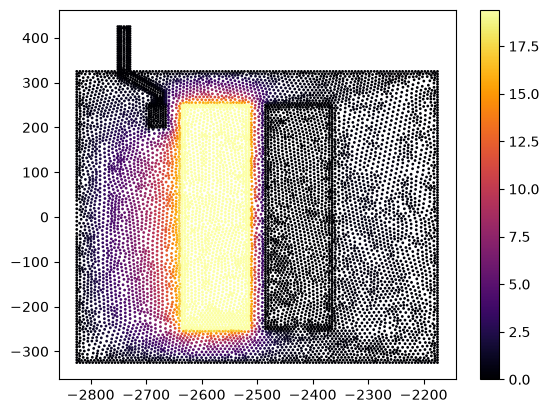

In [21]:
%matplotlib inline
electrostatic_simulation.plot_field(field="V",index=1) # plot magnitude of electric field [V/m]

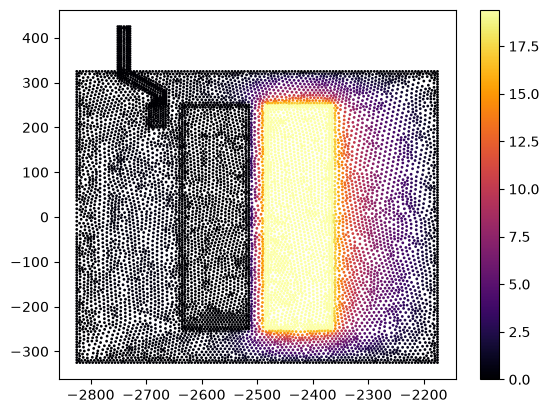

In [22]:
electrostatic_simulation.plot_field(field="V",index=2) # plot magnitude of electric field [V/m]

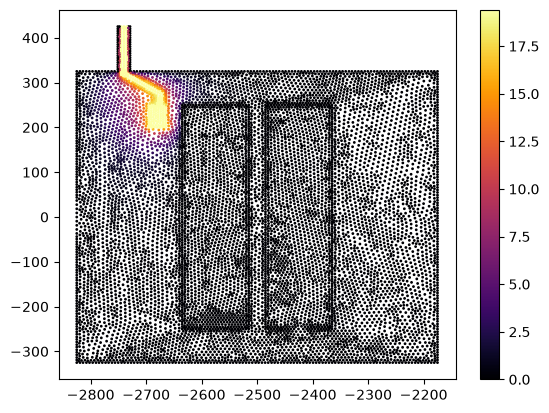

In [23]:
electrostatic_simulation.plot_field(field="V",index=3) # plot magnitude of electric field [V/m]

# Extract simulation results 

The main result of an electrostatic simulation is the Maxwell capacitance matrix.

### <u>What is the Maxwell capacitance matrix?</u>

The Maxwell capacitance matrix describes how charge is distributed among a set of conductors. Its diagonal elements represent the self-capacitance of each conductor, while its off-diagonal elements represent the mutual capacitive coupling between conductors. This matrix forms the foundation for extracting circuit parameters such as the qubit charging energy ($E_C$) and qubit-resonator coupling strengths, along with parasitic couplings if relevant.

For this qubit + claw system we expect:

$$
\mathbf{C} = \begin{pmatrix}
C_{qq} & C_{qc} & C_{qg} \\
C_{cq} & C_{cc} & C_{cg} \\
C_{gq} & C_{gc} & C_{gg}
\end{pmatrix}
$$

where $C_{qq}$ is the qubit self-capacitance, $C_{cc}$ is the coupling claw self-capacitance, $C_{gg}$ is the ground self-capacitance, and the off-diagonal elements are the negatives of the mutual capacitances between conductors. (For this Maxwell capacitance matrix, the diagonal $C_{ii}$ is the total capacitance of conductor $i$ to everything else, while each off-diagonal $C_{ij}$ is the negative of the physical mutual capacitance between conductors $i$ and $j$. The negative signs are why we take absolute values below.)

In [24]:
# extract capacitance matrix 
capacitance_matrix = electrostatic_simulation.get_capacitance_matrix()


capacitance_matrix.columns = [name.replace("1__", "") for name in capacitance_matrix.columns]
capacitance_matrix.index = [name.replace("1__", "") for name in capacitance_matrix.index]
print(capacitance_matrix.columns)
capacitance_matrix



Index(['pad_top', 'pad_bot', 'readout_connector_pad', 'ground'], dtype='object')


,pad_top,pad_bot,readout_connector_pad,ground
pad_top,1.298393e-13,-5.102880e-14,-7.903442e-15,-7.090706e-14
pad_bot,-5.102880e-14,1.270805e-13,-5.986796e-16,-7.545304e-14
readout_connector_pad,-7.903442e-15,-5.986796e-16,6.631034e-14,-5.780822e-14
ground,-7.090706e-14,-7.545304e-14,-5.780822e-14,0.000000e+00


# LOM Analysis

LOM approximates a superconducting circuit as a network of lumped circuit elements (a superconducting quantum circuit). Using capacitances extracted from electrostatic simulations and Josephson junction parameters, LOM enables calculation of circuit-QED Hamiltonian parameters such as the qubit frequency and anharmonicity.


In [25]:
from pypalace.analysis import LOM

from qiskit_metal.analyses.quantization.lumped_capacitive import extract_transmon_coupled_Noscillator
from qiskit_metal.analyses.quantization.constants import Ic_from_Lj

In [26]:
capacitance_matrix = capacitance_matrix.reindex(columns=['ground', 'pad_top', 'pad_bot', 'readout_connector_pad'])

capacitance_matrix = capacitance_matrix.reindex(['ground', 'pad_top', 'pad_bot', 'readout_connector_pad'])
capacitance_matrix

,ground,pad_top,pad_bot,readout_connector_pad
ground,0.000000e+00,-7.090706e-14,-7.545304e-14,-5.780822e-14
pad_top,-7.090706e-14,1.298393e-13,-5.102880e-14,-7.903442e-15
pad_bot,-7.545304e-14,-5.102880e-14,1.270805e-13,-5.986796e-16
readout_connector_pad,-5.780822e-14,-7.903442e-15,-5.986796e-16,6.631034e-14


# Sweeps


In [27]:
import numpy as np
import pandas as pd


def extract_lom_hamiltonian(
    cmat, Ic, CJ, fr, fb,
    labels=None,
    ground="ground",
    qubit_pads=("pad_top", "pad_bot"),
    readout="readout_connector_pad",
    buses=None,
    res_L4_corr=None,
    g_scale=1.0,
    Z0=50.0,
    ng_points=51,
    nmax=40,
    use_metal_constants=True,
    print_info=False,
):
    """Monolithic LOM extraction: floating two-pad transmon + N coupling pads.

    Mirrors qiskit_metal.analyses.quantization.lumped_capacitive
    .extract_transmon_coupled_Noscillator, but reads node names, reorders the
    Maxwell matrix itself, and has no qiskit_metal dependency.

    cmat   : DataFrame (labelled) or ndarray + labels; Maxwell matrix in FARADS.
    Ic     : junction critical current [A];  CJ : junction capacitance [F]
    fr     : readout resonator frequency [GHz]
    fb     : bus resonator frequencies [GHz], order of `buses`
    buses  : bus coupling-pad names (default: all remaining nodes, matrix order)
    res_L4_corr : per resonator [readout, bus1, ...]; 1 -> lambda/4
    use_metal_constants : True -> CODATA-2014 values used inside qiskit-metal.
    """
    # ---------------------------------------------------------------- constants
    if use_metal_constants:
        e, h, hbar = 1.60217657e-19, 6.62606957e-34, 1.0545718e-34
        phi0 = 2.067e-15 / (2 * np.pi)                   # reduced flux quantum
    else:
        e, h = 1.602176634e-19, 6.62607015e-34
        hbar = h / (2 * np.pi)
        phi0 = hbar / (2 * e)

    # ---------------------------------------------------------------- parse + reorder
    if isinstance(cmat, pd.DataFrame):
        names, C = list(cmat.index), cmat.to_numpy(dtype=float)
    else:
        if labels is None:
            raise ValueError("labels is required when cmat is not a DataFrame")
        names, C = list(labels), np.asarray(cmat, dtype=float)
    if C.shape != (len(names), len(names)):
        raise ValueError(f"cmat shape {C.shape} does not match {len(names)} labels")
    if not np.allclose(C, C.T, rtol=1e-3, atol=1e-20):
        raise ValueError("Capacitance matrix is not symmetric")
    # Maxwell matrix: every non-ground row sums to ~0 (Q3D leaves the ground diagonal at 0)
    ng_rows = [i for i, nm in enumerate(names) if nm != ground]
    if not np.allclose(C[ng_rows].sum(axis=1), 0, atol=1e-3 * np.abs(np.diag(C)).max()):
        raise ValueError("Non-ground rows do not sum to ~0: not a Maxwell capacitance matrix")

    qubit_pads = list(qubit_pads)
    if buses is None:
        buses = [n for n in names if n not in (ground, readout, *qubit_pads)]
    buses = list(buses)
    N = 1 + len(buses)                                   # 1 readout + (N-1) buses
    order = buses + [ground] + qubit_pads + [readout]    # qiskit-metal basis
    if sorted(order) != sorted(names):
        raise ValueError(f"Node-name mismatch. Matrix has {names}; expected {order}")
    idx = [names.index(n) for n in order]
    CM = C[np.ix_(idx, idx)]
    res_names = [readout] + buses                        # output order [readout, bus1, ...]

    fb_list = [fb] * (N - 1) if np.isscalar(fb) else list(fb)
    if len(fb_list) != N - 1:
        raise ValueError(f"fb needs {N-1} entries (one per bus), got {len(fb_list)}")
    wr = 2 * np.pi * 1e9 * np.array([fr] + fb_list, dtype=float)       # rad/s

    # ---------------------------------------------------------------- resonator LC
    Cr = 0.5 * np.pi / (wr * Z0)                         # lambda/2 equivalent
    Lr = 1.0 / (wr**2 * Cr)
    if res_L4_corr is not None:
        for i, flag in enumerate(res_L4_corr):
            if flag:
                Cr[i] /= 2.0
                Lr[i] *= 2.0

    # ---------------------------------------------------------------- capacitance bookkeeping
    g_i = N - 1
    q_i = [g_i + 1, g_i + 2]
    r_i = [len(CM) - 1] + list(range(N - 1))             # [readout, bus1, ...]

    Cg = np.array([-CM[q_i[0], g_i], -CM[q_i[1], g_i]])
    Cs = -CM[q_i[0], q_i[1]]
    Cbus = np.array([[-CM[q, r] for r in r_i] for q in q_i])            # (2, N)
    Cbb = np.array([[-CM[a, b] if a != b else 0.0 for b in r_i] for a in r_i])

    C1S = Cg[0] + Cbus[0].sum()
    C2S = Cg[1] + Cbus[1].sum()
    tCSq = Cs + C1S * C2S / (C1S + C2S)
    tCSbus = (Cr - (Cbus[0] + Cbus[1])**2 / (C1S + C2S)
              + Cbus.sum(axis=0) + Cbb.sum(axis=1))
    tCqbus = (C2S * Cbus[0] - Cbus[1] * C1S) / (C1S + C2S)
    tCqbb = Cbb + np.outer(Cbus[0] + Cbus[1], Cbus[0] + Cbus[1]) / (C1S + C2S)
    bbus = (C2S * Cbus[0] - Cbus[1] * C1S) / ((C1S + C2S) * Cs + C1S * C2S)
    Cq = tCSq + CJ

    # ---------------------------------------------------------------- transmon
    LJ = phi0 / Ic
    EJ = phi0**2 / LJ / hbar                             # rad/s
    EC = e**2 / (2 * Cq) / hbar                          # rad/s
    Zqp = np.sqrt(LJ / Cq)

    Ec_J, EJ_J = e**2 / (2 * Cq), Ic * hbar / (2 * e)
    n = np.arange(-nmax, nmax + 1)
    V = -0.5 * (np.eye(len(n), k=1) + np.eye(len(n), k=-1))
    E = np.array([np.linalg.eigvalsh(4 * Ec_J * np.diag((n - ng)**2) + EJ_J * V)[:3]
                  for ng in np.linspace(-1, 1, ng_points)])
    E = E - E[:, [0]]
    fq_Hz = np.mean(E[:, 1]) / h
    alpha_Hz = np.mean(E[:, 2] - 2 * E[:, 1]) / h
    disp_Hz = np.max(-E[:, 1] / h + E[0, 1] / h)
    wq = 2 * np.pi * fq_Hz
    alpha_rad = 2 * np.pi * alpha_Hz

    # ---------------------------------------------------------------- couplings
    Zbus = np.sqrt(Lr / tCSbus)
    gq = 0.5 * wr * bbus * np.sqrt(Zbus / Zqp) * g_scale                # rad/s
    gbb = 0.5 * np.sqrt(np.outer(wr, wr)) * tCqbb / np.sqrt(np.outer(tCSbus, tCSbus))
    np.fill_diagonal(gbb, 0.0)

    # ---------------------------------------------------------------- dispersive shift (Koch)
    w01, w12 = wq, wq + alpha_rad
    chi0 = -2 * gq**2 * w01 / (w01**2 - wr**2)
    chi1 = gq**2 * (1 / (w01 - wr) - 2 / (w12 - wr) + 1 / (w01 + wr) - 2 / (w12 + wr))
    chi_MHz = (chi1 - chi0) / (2 * np.pi * 1e6)          # full |0>->|1> splitting

    # ---------------------------------------------------------------- Purcell (same Q guesses as reference)
    Qres = np.full(N, 1e5)
    Qres[0] = 1e4
    kappa = wr / Qres
    T1bus = (wr**2 - wq**2)**2 / (4 * kappa * gq**2 * wq**2)
    T1 = 1.0 / np.sum(1.0 / T1bus)

    # ---------------------------------------------------------------- pack
    MHz = 2 * np.pi * 1e6
    out = {
        "fQ": fq_Hz / 1e9,                  # GHz
        "EC": EC / MHz,                     # MHz
        "EJ": EJ / (2 * np.pi * 1e9),       # GHz
        "alpha": alpha_Hz / 1e6,            # MHz
        "dispersion": disp_Hz / 1e3,        # kHz
        "gbus": gq / MHz,                   # MHz, order = res_names
        "chi_in_MHz": chi_MHz,              # MHz, order = res_names
        # extras (not in the qiskit-metal dict)
        "res_names": res_names,
        "Cq_fF": Cq * 1e15,
        "LJ_nH": LJ * 1e9,
        "tCqbus_fF": tCqbus * 1e15,
        "T1_purcell_us": T1 * 1e6,
        "g_res_res_MHz": pd.DataFrame(gbb / MHz, index=res_names, columns=res_names),
        "summary": pd.DataFrame(
            {"f_res [GHz]": wr / (2 * np.pi * 1e9), "g [MHz]": gq / MHz,
             "chi [MHz]": chi_MHz, "Cqc [fF]": tCqbus * 1e15,
             "T1_Purcell [us]": T1bus * 1e6}, index=res_names),
    }
    if print_info:
        print(f"fQ = {out['fQ']:.4f} GHz | EC = {out['EC']:.2f} MHz | EJ = {out['EJ']:.3f} GHz | "
              f"alpha = {out['alpha']:.2f} MHz | Cq = {out['Cq_fF']:.3f} fF | "
              f"LJ = {out['LJ_nH']:.3f} nH | charge disp = {out['dispersion']:.3g} kHz | "
              f"T1(Purcell) = {out['T1_purcell_us']:.1f} us")
        print(out["summary"].round(4).to_string())
        print("\nresonator-resonator g [MHz]:")
        print(out["g_res_res_MHz"].round(4).to_string())
    return out

In [28]:
from pint import UnitRegistry
ureg = UnitRegistry()

lom_setup = Dict(junctions=Dict(Lj=12, Cj=2), freq_readout=7.0, freq_bus=[])

ic_amps = Ic_from_Lj(lom_setup.junctions.Lj, "nH", "A")
cj = ureg(f"{lom_setup.junctions.Cj} fF").to("farad").magnitude
fread = ureg(f"{lom_setup.freq_readout} GHz").to("GHz").magnitude
fbus = [ureg(f"{freq} GHz").to("GHz").magnitude for freq in lom_setup.freq_bus]

# derive number of coupling pads
num_cpads = 2
if isinstance(fread, list):
    num_cpads += len(fread) - 1
if isinstance(fbus, list):
    num_cpads += len(fbus) - 1

ham = extract_lom_hamiltonian(
    capacitance_matrix,
    Ic=ic_amps,                     
    CJ=cj,                          
    fr=fread,                       
    fb=fbus,                        
    buses=None,
    res_L4_corr=[1],
    print_info=True
)

# ham

fQ = 4.5743 GHz | EC = 211.16 MHz | EJ = 13.611 GHz | alpha = -237.68 MHz | Cq = 91.732 fF | LJ = 12.000 nH | charge disp = 0.778 kHz | T1(Purcell) = 632.1 us
                       f_res [GHz]  g [MHz]  chi [MHz]  Cqc [fF]  T1_Purcell [us]
readout_connector_pad          7.0  58.2045    -0.2615    3.5767         632.0836

resonator-resonator g [MHz]:
                       readout_connector_pad
readout_connector_pad                    0.0


In [29]:
print(f"EJ/EC = {ham['EJ']*1000/ham['EC']}")

EJ/EC = 64.45704683672034


In [30]:
import re, time
from pathlib import Path
import numpy as np
import pandas as pd
from qiskit_metal import Dict
from qiskit_metal.analyses.sweep_and_optimize.sweeper import Sweeper

# ----------------------------------------------------------------------------- sweep definition
QCOMP, OPTION = "Q0", "pad_width"        # dotted paths work, e.g. "connection_pads.readout.pad_width"
SWEEP_VALUES  = ["400um", "450um", "500um", "550um", "600um"]   # strings WITH units
FE_ORDER, N_MPI = 2, 8
WORKDIR = Path("sweep_pad_width").resolve()
# -----------------------------------------------------------------------------------------------

TERMINALS   = ["pad_top", "pad_bot", "readout_connector_pad"]
GROUP_ORDER = ["ground", *TERMINALS]
BUSES       = []

def _opt_parent(design, qcomp, path):
    """Return (options-dict holding the leaf, leaf key) for a dotted option path."""
    d = design.components[qcomp].options
    *head, last = path.split(".")
    for k in head:
        d = d[k]
    return d, last


class PalaceLOMAnalysis:
    """Minimal QAnalysis-like wrapper so Sweeper can drive: mesh -> Palace electrostatics -> LOM.
    Sweeper calls .run() once per value and stores ._variables for each point."""

    def __init__(self, design, qcomp, option, order=2, n_mpi=8, workdir="sweep"):
        self.design, self.qcomp, self.option = design, qcomp, option
        self.order, self.n_mpi, self.workdir = order, n_mpi, Path(workdir)
        self.setup = Dict(run=Dict())     # Sweeper reads parent.setup.run
        self._variables = Dict()
        self._n = 0

    def run(self, **_ignored):            # Sweeper passes name / box_plus_buffer kwargs: unused here
        holder, key = _opt_parent(self.design, self.qcomp, self.option)
        val = holder[key]
        d = self.workdir / f"{self._n:02d}_{re.sub(r'[^0-9A-Za-z]+', '', str(val))}"
        self._n += 1
        d.mkdir(parents=True, exist_ok=True)
        t0 = time.perf_counter()
        try:
            # ---- mesh (same attribute numbering as the main notebook)
            st, attrs, k = mesh.get_quantum_metal_surfaces(self.design), {}, 1
            for _, r in st.iterrows():
                if r["subtract"] == False:
                    attrs[(r["component_id"], r["name"])] = k
                    k += 1
            msh = str(d / "chip.msh")
            at = mesh.mesh_Quantum_Metal_design(self.design, output_mesh=msh, Attributes=attrs)

            def ID(name):
                hit = at[at["Name"].str.endswith(name)]
                assert len(hit) == 1, f"mesh attribute '{name}' not unique/found"
                return int(hit["ID"].iloc[0])

            # ---- Palace electrostatic config (only Output/Mesh paths change between points)
            cfg = Config(str(d / "config.json"))
            cfg.add_Problem(Type="Electrostatic", Output=str(d / "out"))
            cfg.add_Model(Mesh=msh, L0=1e-6)
            cfg.add_Domains(Materials=[
                Domains.Material(Attributes=[ID("substrate")], Permeability=1.0, Permittivity=11.45, LossTan=1e-7),
                Domains.Material([ID("air")], 1.0, 1.0, 0.0)])
            cfg.add_Boundaries(BCs=[Boundaries.Ground(Attributes=[ID("ground_plane"), ID("far_field")])]
                                   + [Boundaries.Terminal(Index=i + 1, Attributes=[ID(n)])
                                      for i, n in enumerate(TERMINALS)])
            cfg.add_Solver(Simulation=Solver.Electrostatic(Save=0),     # Save=0: skip Paraview dumps
                           Order=self.order,
                           Linear=Solver.Linear(Type="BoomerAMG", KSPType="CG", Tol=1e-10, MaxIts=200))
            cfg.save_config(check_validity=True)

            sim = Simulation(cfg, path_to_palace)
            sim.run(n=self.n_mpi)

            # ---- capacitance matrix -> LOM
            C = sim.get_capacitance_matrix()
            C.columns = [c.replace("1__", "") for c in C.columns]
            C.index   = [c.replace("1__", "") for c in C.index]
            C = C.reindex(index=GROUP_ORDER, columns=GROUP_ORDER)
            C = 0.5 * (C + C.T)

            ## Conversions ...
            ic_amps = Ic_from_Lj(lom_setup.junctions.Lj, "nH", "A")
            cj = ureg(f"{lom_setup.junctions.Cj} fF").to("farad").magnitude
            fread = ureg(f"{lom_setup.freq_readout} GHz").to("GHz").magnitude
            fbus = [ureg(f"{freq} GHz").to("GHz").magnitude for freq in lom_setup.freq_bus]

            ham = extract_lom_hamiltonian(C, Ic=ic_amps, CJ=cj, fr=fread, fb=fbus, buses=BUSES)

            # NEW Dict every run: Sweeper stores a reference, so never mutate the previous one
            self._variables = Dict(option_value=val, cmat=C, ham=ham, wall_s=time.perf_counter() - t0)
        except Exception as ex:
            self._variables = Dict(option_value=val, error=repr(ex))
            raise                          # Sweeper logs a warning and carries on with the next value


analysis = PalaceLOMAnalysis(design, QCOMP, OPTION, FE_ORDER, N_MPI, WORKDIR)
sweeper  = Sweeper(analysis)

holder, key = _opt_parent(design, QCOMP, OPTION)
orig_value  = holder[key]
try:
    all_sweep, status = sweeper.run_sweep(QCOMP, OPTION, SWEEP_VALUES)
finally:                                   # Sweeper leaves the LAST value in the design: restore it
    holder, key = _opt_parent(design, QCOMP, OPTION)
    holder[key] = orig_value
    design.rebuild()

assert status == 0, (f"Sweeper status {status}: 1=component not found, 2=empty option name, "
                     f"3=bad option path, 4=empty sweep, 5=leaf key missing")
failed = [v for v, e in all_sweep.items() if "error" in e["variables"]]
print(f"{len(all_sweep) - len(failed)}/{len(all_sweep)} points OK" + (f" | failed: {failed}" if failed else ""))

Info    : Meshing 1D...nts                                                                                                                
Info    : [  0%] Meshing curve 25 (Line)
Info    : [ 10%] Meshing curve 26 (Line)
Info    : [ 10%] Meshing curve 27 (Line)
Info    : [ 10%] Meshing curve 28 (Line)
Info    : [ 10%] Meshing curve 29 (Line)
Info    : [ 10%] Meshing curve 30 (Line)
Info    : [ 10%] Meshing curve 31 (Line)
Info    : [ 20%] Meshing curve 32 (Line)
Info    : [ 20%] Meshing curve 47 (Line)
Info    : [ 20%] Meshing curve 48 (Line)
Info    : [ 20%] Meshing curve 49 (Line)
Info    : [ 20%] Meshing curve 50 (Line)
Info    : [ 20%] Meshing curve 51 (Line)
Info    : [ 30%] Meshing curve 52 (Line)
Info    : [ 30%] Meshing curve 53 (Line)
Info    : [ 30%] Meshing curve 54 (Line)
Info    : [ 30%] Meshing curve 55 (Line)
Info    : [ 30%] Meshing curve 56 (Line)
Info    : [ 30%] Meshing curve 57 (Line)
Info    : [ 40%] Meshing curve 58 (Line)
Info    : [ 40%] Meshing curve 59 (Line)


In [31]:
all_sweep

{'400um': {'option_name': 'pad_width',
  'variables': {'option_value': '400um',
   'cmat':                              ground       pad_top       pad_bot  \
   ground                 0.000000e+00 -5.445043e-14 -5.689720e-14   
   pad_top               -5.445043e-14  9.282978e-14 -3.352935e-14   
   pad_bot               -5.689720e-14 -3.352935e-14  9.083004e-14   
   readout_connector_pad -6.822957e-15 -4.849994e-15 -4.034876e-16   
   
                          readout_connector_pad  
   ground                         -6.822957e-15  
   pad_top                        -4.849994e-15  
   pad_bot                        -4.034876e-16  
   readout_connector_pad           1.207644e-14  ,
   'ham': {'fQ': 5.394057296597573,
    'EC': 299.5192710779779,
    'EJ': 13.610809273781989,
    'alpha': -347.0254681350193,
    'dispersion': 26.343512927055357,
    'gbus': array([33.01010662]),
    'chi_in_MHz': array([-0.2462]),
    'res_names': ['readout_connector_pad'],
    'Cq_fF': 64.67105783061

,pad_width [um],f01 [GHz],alpha [MHz],E_C [MHz],E_J/E_C,C_q [fF],|g| readout [MHz],chi readout [MHz],T1 Purcell [us],wall [s]
0,400.0,5.3941,-347.0255,299.5193,45.4422,64.6711,33.0101,-0.2462,710.2712,14.7009
1,450.0,5.1479,-311.3207,271.1499,50.1966,71.4373,30.3763,-0.1474,1176.7225,16.7473
2,500.0,4.9257,-281.2686,246.9153,55.1234,78.4489,28.2275,-0.0950,1799.1880,15.5617
3,550.0,4.7243,-255.7156,226.0435,60.2132,85.6925,25.5650,-0.0605,2773.8718,14.0419
4,600.0,4.5176,-231.0827,205.6844,66.1733,94.1745,21.9541,-0.0348,4723.8164,14.9347


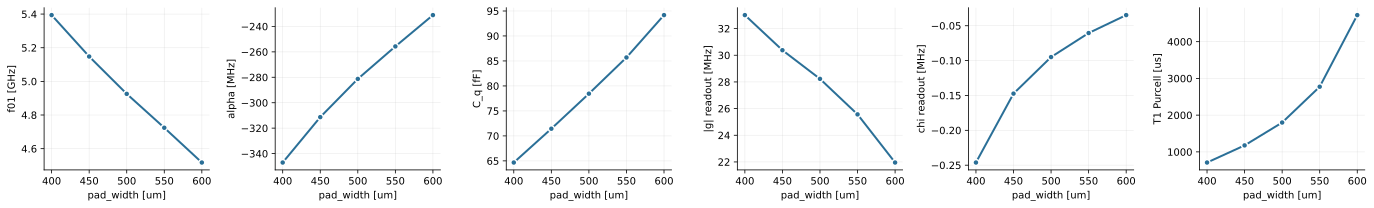

In [32]:
import matplotlib.pyplot as plt

rows = []
for val, entry in all_sweep.items():
    v = entry["variables"]
    if "error" in v:
        continue
    h = v["ham"]
    rows.append({
        f"{OPTION} [um]":     design.parse_value(val) * 1e3,         # parse_value returns mm
        "f01 [GHz]":          h["fQ"],
        "alpha [MHz]":        h["alpha"],
        "E_C [MHz]":          h["EC"],
        "E_J/E_C":            h["EJ"] * 1e3 / h["EC"],
        "C_q [fF]":           h["Cq_fF"],
        "|g| readout [MHz]":  abs(h["gbus"][0]),
        "chi readout [MHz]":  h["chi_in_MHz"][0],
        "T1 Purcell [us]":    h["T1_purcell_us"],
        "wall [s]":           v["wall_s"],
    })
res = pd.DataFrame(rows).sort_values(f"{OPTION} [um]").reset_index(drop=True)
display(res.round(4))

# small multiples, one quantity per axis (no dual axes)
x = res[f"{OPTION} [um]"]
panels = ["f01 [GHz]", "alpha [MHz]", "C_q [fF]", "|g| readout [MHz]", "chi readout [MHz]", "T1 Purcell [us]"]
fig, axes = plt.subplots(1, len(panels), figsize=(3.2 * len(panels), 3.0))
for ax, col in zip(axes, panels):
    ax.plot(x, res[col], "-o", color="#2a6f97", lw=2, ms=6, mec="white", mew=1.5)
    ax.set_xlabel(f"{OPTION} [um]"); ax.set_ylabel(col)
    ax.grid(alpha=0.25, lw=0.6)
    for s in ("top", "right"): ax.spines[s].set_visible(False)
plt.tight_layout(); plt.show()


In [37]:
design.components[QCOMP].options.pad_width = '500 um'
design.rebuild()

OPTION = 'pad_height'
SWEEP_VALUES = ["70 um", "90 um", "120 um", "150 um"]

analysis = PalaceLOMAnalysis(design, QCOMP, OPTION, FE_ORDER, N_MPI, WORKDIR)
sweeper  = Sweeper(analysis)

holder, key = _opt_parent(design, QCOMP, OPTION)
orig_value  = holder[key]
try:
    all_sweep, status = sweeper.run_sweep(QCOMP, OPTION, SWEEP_VALUES)
finally:                                   # Sweeper leaves the LAST value in the design: restore it
    holder, key = _opt_parent(design, QCOMP, OPTION)
    holder[key] = orig_value
    design.rebuild()

assert status == 0, (f"Sweeper status {status}: 1=component not found, 2=empty option name, "
                     f"3=bad option path, 4=empty sweep, 5=leaf key missing")
failed = [v for v, e in all_sweep.items() if "error" in e["variables"]]
print(f"{len(all_sweep) - len(failed)}/{len(all_sweep)} points OK" + (f" | failed: {failed}" if failed else ""))

Info    : Meshing 1D...nts                                                                                                                
Info    : [  0%] Meshing curve 25 (Line)
Info    : [ 10%] Meshing curve 26 (Line)
Info    : [ 10%] Meshing curve 27 (Line)
Info    : [ 10%] Meshing curve 28 (Line)
Info    : [ 10%] Meshing curve 29 (Line)
Info    : [ 10%] Meshing curve 30 (Line)
Info    : [ 10%] Meshing curve 31 (Line)
Info    : [ 20%] Meshing curve 32 (Line)
Info    : [ 20%] Meshing curve 47 (Line)
Info    : [ 20%] Meshing curve 48 (Line)
Info    : [ 20%] Meshing curve 49 (Line)
Info    : [ 20%] Meshing curve 50 (Line)
Info    : [ 20%] Meshing curve 51 (Line)
Info    : [ 30%] Meshing curve 52 (Line)
Info    : [ 30%] Meshing curve 53 (Line)
Info    : [ 30%] Meshing curve 54 (Line)
Info    : [ 30%] Meshing curve 55 (Line)
Info    : [ 30%] Meshing curve 56 (Line)
Info    : [ 30%] Meshing curve 57 (Line)
Info    : [ 40%] Meshing curve 58 (Line)
Info    : [ 40%] Meshing curve 59 (Line)


,pad_height [um],f01 [GHz],alpha [MHz],E_C [MHz],E_J/E_C,C_q [fF],|g| readout [MHz],chi readout [MHz],T1 Purcell [us],wall [s]
0,70.0,5.3552,-341.2114,294.9304,46.1492,65.6773,28.4290,-0.1726,1012.8219,15.8217
1,90.0,5.1531,-312.0507,271.7345,50.0886,71.2836,27.9034,-0.1252,1385.0719,12.8278
2,120.0,4.9257,-281.2686,246.9153,55.1234,78.4489,28.2275,-0.0950,1799.1880,15.0789
3,150.0,4.7443,-258.1812,228.0683,59.6787,84.9317,26.8128,-0.0682,2465.1497,15.2322


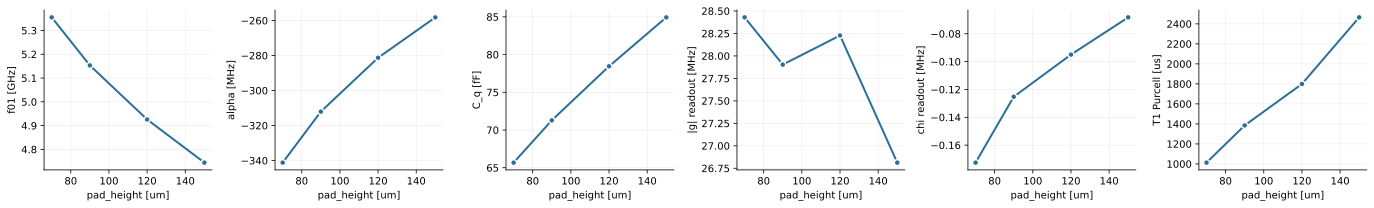

In [38]:
import matplotlib.pyplot as plt

rows = []
for val, entry in all_sweep.items():
    v = entry["variables"]
    if "error" in v:
        continue
    h = v["ham"]
    rows.append({
        f"{OPTION} [um]":     design.parse_value(val) * 1e3,         # parse_value returns mm
        "f01 [GHz]":          h["fQ"],
        "alpha [MHz]":        h["alpha"],
        "E_C [MHz]":          h["EC"],
        "E_J/E_C":            h["EJ"] * 1e3 / h["EC"],
        "C_q [fF]":           h["Cq_fF"],
        "|g| readout [MHz]":  abs(h["gbus"][0]),
        "chi readout [MHz]":  h["chi_in_MHz"][0],
        "T1 Purcell [us]":    h["T1_purcell_us"],
        "wall [s]":           v["wall_s"],
    })
res = pd.DataFrame(rows).sort_values(f"{OPTION} [um]").reset_index(drop=True)
display(res.round(4))

# small multiples, one quantity per axis (no dual axes)
x = res[f"{OPTION} [um]"]
panels = ["f01 [GHz]", "alpha [MHz]", "C_q [fF]", "|g| readout [MHz]", "chi readout [MHz]", "T1 Purcell [us]"]
fig, axes = plt.subplots(1, len(panels), figsize=(3.2 * len(panels), 3.0))
for ax, col in zip(axes, panels):
    ax.plot(x, res[col], "-o", color="#2a6f97", lw=2, ms=6, mec="white", mew=1.5)
    ax.set_xlabel(f"{OPTION} [um]"); ax.set_ylabel(col)
    ax.grid(alpha=0.25, lw=0.6)
    for s in ("top", "right"): ax.spines[s].set_visible(False)
plt.tight_layout(); plt.show()

In [39]:
design.components[QCOMP].options.pad_width = '500 um'
design.rebuild()

OPTION = 'pad_height'
SWEEP_VALUES = ["70 um", "90 um", "120 um", "150 um"]

analysis = PalaceLOMAnalysis(design, QCOMP, OPTION, FE_ORDER, N_MPI, WORKDIR)
sweeper  = Sweeper(analysis)

holder, key = _opt_parent(design, QCOMP, OPTION)
orig_value  = holder[key]
try:
    all_sweep, status = sweeper.run_sweep(QCOMP, OPTION, SWEEP_VALUES)
finally:                                   # Sweeper leaves the LAST value in the design: restore it
    holder, key = _opt_parent(design, QCOMP, OPTION)
    holder[key] = orig_value
    design.rebuild()

assert status == 0, (f"Sweeper status {status}: 1=component not found, 2=empty option name, "
                     f"3=bad option path, 4=empty sweep, 5=leaf key missing")
failed = [v for v, e in all_sweep.items() if "error" in e["variables"]]
print(f"{len(all_sweep) - len(failed)}/{len(all_sweep)} points OK" + (f" | failed: {failed}" if failed else ""))

Info    : Meshing 1D...nts                                                                                                                
Info    : [  0%] Meshing curve 25 (Line)
Info    : [ 10%] Meshing curve 26 (Line)
Info    : [ 10%] Meshing curve 27 (Line)
Info    : [ 10%] Meshing curve 28 (Line)
Info    : [ 10%] Meshing curve 29 (Line)
Info    : [ 10%] Meshing curve 30 (Line)
Info    : [ 10%] Meshing curve 31 (Line)
Info    : [ 20%] Meshing curve 32 (Line)
Info    : [ 20%] Meshing curve 47 (Line)
Info    : [ 20%] Meshing curve 48 (Line)
Info    : [ 20%] Meshing curve 49 (Line)
Info    : [ 20%] Meshing curve 50 (Line)
Info    : [ 20%] Meshing curve 51 (Line)
Info    : [ 30%] Meshing curve 52 (Line)
Info    : [ 30%] Meshing curve 53 (Line)
Info    : [ 30%] Meshing curve 54 (Line)
Info    : [ 30%] Meshing curve 55 (Line)
Info    : [ 30%] Meshing curve 56 (Line)
Info    : [ 30%] Meshing curve 57 (Line)
Info    : [ 40%] Meshing curve 58 (Line)
Info    : [ 40%] Meshing curve 59 (Line)


,pad_height [um],f01 [GHz],alpha [MHz],E_C [MHz],E_J/E_C,C_q [fF],|g| readout [MHz],chi readout [MHz],T1 Purcell [us],wall [s]
0,70.0,5.3552,-341.2114,294.9304,46.1492,65.6773,28.4290,-0.1726,1012.8219,14.6909
1,90.0,5.1531,-312.0507,271.7345,50.0886,71.2836,27.9034,-0.1252,1385.0719,15.3097
2,120.0,4.9257,-281.2686,246.9153,55.1234,78.4489,28.2275,-0.0950,1799.1880,13.9027
3,150.0,4.7443,-258.1812,228.0683,59.6787,84.9317,26.8128,-0.0682,2465.1497,15.1778


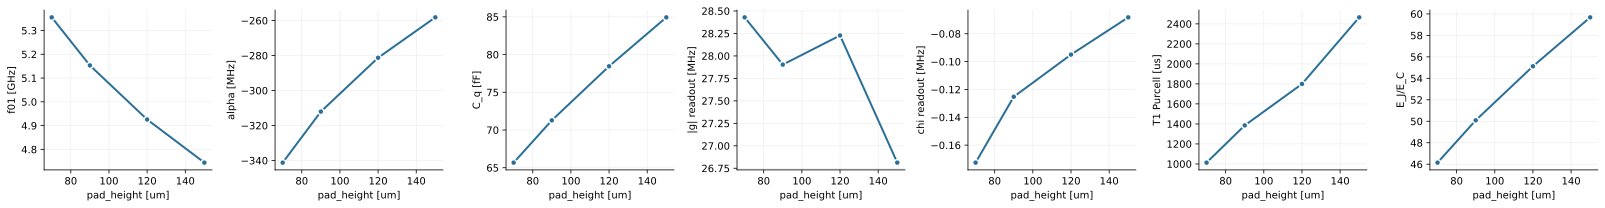

In [40]:
import matplotlib.pyplot as plt

rows = []
for val, entry in all_sweep.items():
    v = entry["variables"]
    if "error" in v:
        continue
    h = v["ham"]
    rows.append({
        f"{OPTION} [um]":     design.parse_value(val) * 1e3,         # parse_value returns mm
        "f01 [GHz]":          h["fQ"],
        "alpha [MHz]":        h["alpha"],
        "E_C [MHz]":          h["EC"],
        "E_J/E_C":            h["EJ"] * 1e3 / h["EC"],
        "C_q [fF]":           h["Cq_fF"],
        "|g| readout [MHz]":  abs(h["gbus"][0]),
        "chi readout [MHz]":  h["chi_in_MHz"][0],
        "T1 Purcell [us]":    h["T1_purcell_us"],
        "wall [s]":           v["wall_s"],
    })
res = pd.DataFrame(rows).sort_values(f"{OPTION} [um]").reset_index(drop=True)
display(res.round(4))

# small multiples, one quantity per axis (no dual axes)
x = res[f"{OPTION} [um]"]
panels = ["f01 [GHz]", "alpha [MHz]", "C_q [fF]", "|g| readout [MHz]", "chi readout [MHz]", "T1 Purcell [us]", "E_J/E_C"]
fig, axes = plt.subplots(1, len(panels), figsize=(3.2 * len(panels), 3.0))
for ax, col in zip(axes, panels):
    ax.plot(x, res[col], "-o", color="#2a6f97", lw=2, ms=6, mec="white", mew=1.5)
    ax.set_xlabel(f"{OPTION} [um]"); ax.set_ylabel(col)
    ax.grid(alpha=0.25, lw=0.6)
    for s in ("top", "right"): ax.spines[s].set_visible(False)
plt.tight_layout(); plt.show()